# 08 - Appendix: Other Experiments

This notebook keeps the experiments that are not in the main notebooks. Each one was useful during the project, but its conclusion is already given in one line in the main notebooks.

- A. Raw text vs cleaned text
- B. Binary TF-IDF on one split, and the seed check
- C. Text vs image per category
- D. Other ways to combine text and image
- E. Image model variants

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC

from src.categories import CATEGORY_NAMES
from src.data_utils import load_merged_data
from src.metrics import compute_per_class_metrics

data = pd.read_csv("../data/processed/text_train_processed.csv")
model_train = data[data["split"] == "train"].copy()
model_validation = data[data["split"] == "validation"].copy()
y_train = model_train["prdtypecode"]
y_validation = model_validation["prdtypecode"]

# Baseline text model from notebook 03 (50000 features, normal TF-IDF)
vectorizer = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), min_df=2)
X_train = vectorizer.fit_transform(model_train["text_combined"])
X_validation = vectorizer.transform(model_validation["text_combined"])
text_predictions = LinearSVC(random_state=42).fit(X_train, y_train).predict(X_validation)
text_weighted_f1 = f1_score(y_validation, text_predictions, average="weighted")
text_macro_f1 = f1_score(y_validation, text_predictions, average="macro")
print(f"Baseline weighted F1: {text_weighted_f1:.4f}")

Baseline weighted F1: 0.8274


## A. Raw text vs cleaned text

Main result (notebook 03): cleaning does not change the score. Here are the details.

In [2]:
raw_data = load_merged_data()
raw_text = raw_data["designation"].fillna("") + " " + raw_data["description"].fillna("")

model_train["text_raw"] = model_train["row_id"].map(raw_text)
model_validation["text_raw"] = model_validation["row_id"].map(raw_text)

raw_vectorizer = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), min_df=2)
X_train_raw = raw_vectorizer.fit_transform(model_train["text_raw"])
X_validation_raw = raw_vectorizer.transform(model_validation["text_raw"])

raw_model = LinearSVC(random_state=42)
raw_model.fit(X_train_raw, y_train)
raw_predictions = raw_model.predict(X_validation_raw)

raw_weighted_f1 = f1_score(y_validation, raw_predictions, average="weighted")
raw_macro_f1 = f1_score(y_validation, raw_predictions, average="macro")

cleaning_results = pd.DataFrame({
    "text used": ["raw text", "cleaned text"],
    "weighted_f1": [raw_weighted_f1, text_weighted_f1],
    "macro_f1": [raw_macro_f1, text_macro_f1],
})
cleaning_results.rename(columns={"text used": "Text", "weighted_f1": "Weighted F1", "macro_f1": "Macro F1"}).style.hide(axis="index").format(precision=4)


Text,Weighted F1,Macro F1
raw text,0.8276,0.8167
cleaned text,0.8274,0.8156


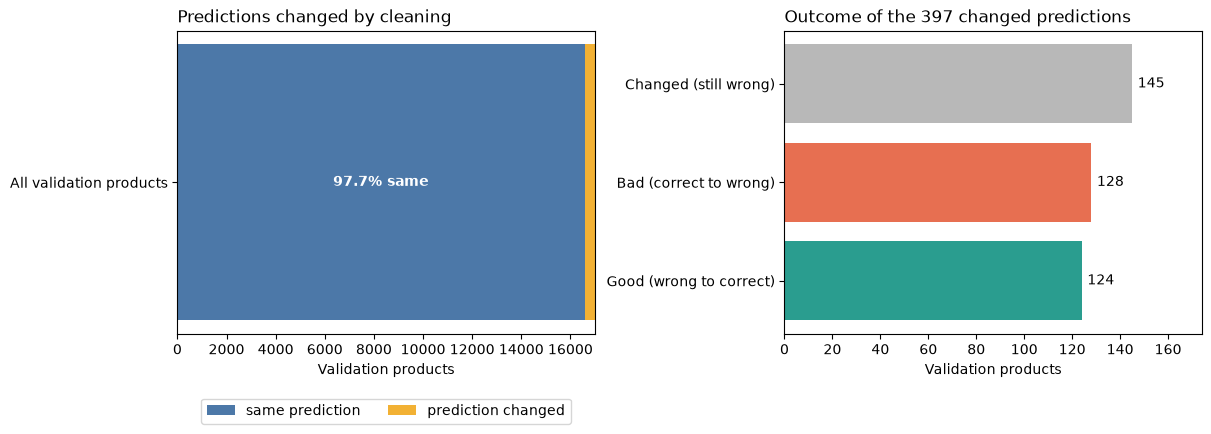

Products with identical predictions: 97.7%
Net change in correct classifications: -4


In [3]:
prediction_changed = raw_predictions != text_predictions
same_count = np.sum(~prediction_changed)
changed_count = np.sum(prediction_changed)

raw_correct = raw_predictions == y_validation.to_numpy()
clean_correct = text_predictions == y_validation.to_numpy()

change_outcomes = pd.Series({
    "Good (wrong to correct)": np.sum(~raw_correct & clean_correct),
    "Bad (correct to wrong)": np.sum(raw_correct & ~clean_correct),
    "Changed (still wrong)": np.sum(prediction_changed & ~raw_correct & ~clean_correct),
})

fig, (ax_pct, ax_breakdown) = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

# Overview bar
ax_pct.barh(["All validation products"], [same_count], color="#4c78a8", label="same prediction")
ax_pct.barh(["All validation products"], [changed_count], left=[same_count], color="#f2b134", label="prediction changed")
ax_pct.set_xlim(0, len(y_validation))
ax_pct.set_title("Predictions changed by cleaning", loc="left")
ax_pct.set_xlabel("Validation products")
ax_pct.text(same_count / 2, 0, f"{same_count / len(y_validation):.1%} same", ha="center", va="center", color="white", fontweight="bold")
ax_pct.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=2)

# Outcome breakdown
bars = ax_breakdown.barh(change_outcomes.index, change_outcomes.values, color=["#2a9d8f", "#e76f51", "#b8b8b8"])
ax_breakdown.set_title(f"Outcome of the {changed_count} changed predictions", loc="left")
ax_breakdown.set_xlabel("Validation products")
ax_breakdown.bar_label(bars, fmt="%d", padding=4)
ax_breakdown.set_xlim(0, change_outcomes.max() * 1.2)

plt.show()

print(f"Products with identical predictions: {same_count / len(y_validation):.1%}")
print(f"Net change in correct classifications: {clean_correct.sum() - raw_correct.sum():+d}")


In [4]:
# Print real examples comparing raw text vs cleaned text where cleaning hurt
bad_mask = (raw_predictions == y_validation.to_numpy()) & (text_predictions != y_validation.to_numpy())
bad_cases = model_validation[bad_mask].copy()
bad_cases['raw_pred'] = raw_predictions[bad_mask]
bad_cases['clean_pred'] = text_predictions[bad_mask]
bad_cases['raw_text'] = bad_cases['row_id'].map(raw_text)

for i, (_, row) in enumerate(bad_cases.head(3).iterrows(), 1):
    print(f"Example {i}: True Category {row['prdtypecode']} (Raw predicted: {row['raw_pred']} [Correct] to Clean predicted: {row['clean_pred']} [Wrong])")
    print(f"  RAW:   {repr(row['raw_text'][:105])}")
    print(f"  CLEAN: {repr(row['text_combined'][:105])}\n")


Example 1: True Category 10 (Raw predicted: 10 [Correct] to Clean predicted: 2705 [Wrong])
  RAW:   "L'avant Scene N° 190 Meurtres En Fa Diese -Sait On Jamais "
  CLEAN: "l'avant scene n° 190 meurtres en fa diese -sait on jamais"

Example 2: True Category 1320 (Raw predicted: 1320 [Correct] to Clean predicted: 2060 [Wrong])
  RAW:   'Suspension Décoration Murale Merlin <div class="rakuten_rich_content" ><div> <h3>Suspension décoration mu'
  CLEAN: 'suspension décoration murale merlin suspension décoration murale sur le thème merlin 100% polyester'

Example 3: True Category 10 (Raw predicted: 10 [Correct] to Clean predicted: 2280 [Wrong])
  RAW:   'Magies Noires Ou Les Magies Qui Font Peur '
  CLEAN: 'magies noires ou les magies qui font peur'



### Analysis

- Raw text and cleaned text give almost the same score (0.8276 against 0.8274).
- 97.7% of products get the same prediction. The few changes go both ways.
- TF-IDF already gives little weight to rare HTML tags, so removing them changes little.

## B. Binary TF-IDF on one split, and the seed check

With binary TF-IDF, each word counts once if it appears, however many times it is repeated. Main result (notebook 03_2): binary TF-IDF is kept after a grid search with cross-validation on train.

In [5]:
# Train Linear SVM with binary=True to neutralize keyword duplication
binary_vectorizer = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), min_df=2, binary=True)
X_train_bin = binary_vectorizer.fit_transform(model_train["text_combined"])
X_validation_bin = binary_vectorizer.transform(model_validation["text_combined"])

binary_model = LinearSVC(random_state=42)
binary_model.fit(X_train_bin, y_train)
binary_predictions = binary_model.predict(X_validation_bin)

binary_weighted_f1 = f1_score(y_validation, binary_predictions, average="weighted")
binary_macro_f1 = f1_score(y_validation, binary_predictions, average="macro")

# Compare standard TF-IDF vs Binary TF-IDF
binary_comparison = pd.DataFrame({
    "TF-IDF Mode": ["Standard (Frequency-weighted)", "Binary (Word Presence Only)"],
    "Weighted F1": [text_weighted_f1, binary_weighted_f1],
    "Macro F1": [text_macro_f1, binary_macro_f1],
})
display(binary_comparison.round(4))

# Check how many of the 128 hurt cases were recovered
recovered_count = np.sum(binary_predictions[bad_mask] == y_validation.to_numpy()[bad_mask])
print(f"Binary TF-IDF recovers {recovered_count} of the {np.sum(bad_mask)} cases hurt by cleaning ({recovered_count / np.sum(bad_mask):.1%}).")
print(f"Overall Weighted F1 improves from {text_weighted_f1:.4f} to {binary_weighted_f1:.4f}.")


,TF-IDF Mode,Weighted F1,Macro F1
0,Standard (Frequency-weighted),0.8274,0.8156
1,Binary (Word Presence Only),0.8313,0.8192


Binary TF-IDF recovers 58 of the 128 cases hurt by cleaning (45.3%).
Overall Weighted F1 improves from 0.8274 to 0.8313.


### Analysis

- Some products were hurt by cleaning because sellers repeat the title inside the description. Repeated words get more weight. For example, *décoration* repeated several times pushes a baby product (1320) to Home Decor (2060).
- With binary TF-IDF, 58 of these 128 errors are fixed, and weighted F1 goes from 0.8274 to 0.8313.
- Binary TF-IDF was chosen by looking at validation errors. The next section checks if the gain is real.

In [6]:
from sklearn.model_selection import train_test_split

all_text = data["text_combined"]
all_labels = data["prdtypecode"]

seed_rows = []
for seed in [0, 1, 2, 3, 4]:
    train_idx, val_idx = train_test_split(
        data.index, test_size=0.20, random_state=seed, stratify=all_labels
    )
    row = {"seed": seed}
    for name, is_binary in [("normal", False), ("binary", True)]:
        vec = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), min_df=2, binary=is_binary)
        X_tr = vec.fit_transform(all_text[train_idx])
        X_va = vec.transform(all_text[val_idx])
        model = LinearSVC(random_state=42).fit(X_tr, all_labels[train_idx])
        row[name] = f1_score(all_labels[val_idx], model.predict(X_va), average="weighted")
    seed_rows.append(row)

seed_results = pd.DataFrame(seed_rows)
seed_results["gain"] = seed_results["binary"] - seed_results["normal"]
display(seed_results.rename(columns={"seed": "Seed", "normal": "Normal TF-IDF", "binary": "Binary TF-IDF", "gain": "Gain"}).style.hide(axis="index").format(precision=4))
print(f"\nAverage gain:        {seed_results['gain'].mean():+.4f}")
print(f"Gain on every seed:  {(seed_results['gain'] > 0).all()}")
print(f"Normal F1 spread:    {seed_results['normal'].max() - seed_results['normal'].min():.4f}")

Seed,Normal TF-IDF,Binary TF-IDF,Gain
0,0.8260,0.8311,0.0051
1,0.8213,0.8254,0.0041
2,0.8242,0.8285,0.0044
3,0.8258,0.8255,-0.0004
4,0.8284,0.8316,0.0033



Average gain:        +0.0033
Gain on every seed:  False
Normal F1 spread:    0.0071


### Analysis

- Binary wins on 4 of 5 seeds. The average gain is 0.33 points.
- The score itself moves by 0.71 points between seeds, twice the gain.
- With 50000 features, the binary gain is too small to be sure. It is tested again in the optimisation notebook (04).

## C. Text vs image per category

F1 for each category, for the text model (binary TF-IDF, 50000 features) and the image model (frozen ResNet18). Both are scored on the same 16984 validation products. Main result (notebook 04): the image helps most on book categories.

In [7]:
from src.metrics import compute_per_class_metrics

# Image predictions saved by 03_modeling_image.ipynb
image_predictions = pd.read_csv("../data/processed/image_validation_predictions.csv")

# Keep only products scored by both models
text_frame = pd.DataFrame({
    "row_id": model_validation["row_id"].to_numpy(),
    "true": y_validation.to_numpy(),
    "text_pred": binary_predictions,
})
both = text_frame.merge(image_predictions[["row_id", "predicted_prdtypecode"]], on="row_id")
print(f"Text validation products:  {len(text_frame)}")
print(f"Image validation products: {len(image_predictions)}")
print(f"Scored by both:            {len(both)}\n")

labels = sorted(both["true"].unique())
text_scores = compute_per_class_metrics(both["true"], both["text_pred"], labels)
image_scores = compute_per_class_metrics(both["true"], both["predicted_prdtypecode"], labels)

side_by_side = pd.DataFrame({
    "prdtypecode": labels,
    "text_precision": text_scores["precision"],
    "text_recall": text_scores["recall"],
    "text_f1": text_scores["f1"],
    "image_precision": image_scores["precision"],
    "image_recall": image_scores["recall"],
    "image_f1": image_scores["f1"],
    "support": text_scores["support"],
}).sort_values("text_f1")

side_by_side.rename(columns={
    "prdtypecode": "Code", "text_precision": "Text precision", "text_recall": "Text recall", "text_f1": "Text F1",
    "image_precision": "Image precision", "image_recall": "Image recall", "image_f1": "Image F1", "support": "Products",
}).style.hide(axis="index").format(precision=3)

Text validation products:  16984
Image validation products: 16984
Scored by both:            16984



Code,Text precision,Text recall,Text F1,Image precision,Image recall,Image F1,Products
10,0.523,0.543,0.533,0.519,0.281,0.365,623
1281,0.683,0.558,0.614,0.312,0.060,0.101,414
1180,0.814,0.601,0.692,0.301,0.144,0.195,153
2705,0.700,0.714,0.707,0.577,0.634,0.604,552
40,0.759,0.697,0.727,0.354,0.384,0.369,502
1280,0.737,0.719,0.728,0.315,0.352,0.333,974
2403,0.749,0.750,0.749,0.591,0.479,0.529,955
2582,0.788,0.734,0.760,0.324,0.425,0.367,518
2280,0.757,0.806,0.781,0.475,0.804,0.597,952
1140,0.794,0.796,0.795,0.465,0.573,0.513,534


### Analysis

- Text: weighted F1 0.83. Image: weighted F1 0.48.
- Text is better on every category.
- Weakest text categories: Used Books (0.53), Board Games (0.61), Wargames (0.69), New Books (0.71).
- The image model comes closest to text on New Books (gap 0.10), Cards (0.11), Used Books (0.17) and Magazines (0.18). Book categories are where text is weakest, so combining both models may help there.
- The image model is close to useless for Game Accessories, Board Games, Garden Tools and Pets (image F1 about 0.10).

## D. Other ways to combine text and image

Main result (notebook 04): equal soft voting on CamemBERT, SVM and image is the final model. A learned combination (Random Forest) was tried there and not kept, because it learns from the validation products it is scored on. Here are the other learned combinations we tried. All are scored with 5-fold cross-validation on the 16984 validation products.

In [8]:
validation = model_validation[["row_id", "prdtypecode"]]
svm = pd.read_csv("../data/processed/text_validation_probabilities.csv")
image = pd.read_csv("../data/processed/image_validation_predictions.csv")
camembert = pd.read_csv("../data/processed/camembert_validation_probabilities.csv")
classes = np.array([int(c) for c in svm.columns[1:]])

image = image[["row_id"] + [f"prob_{c}" for c in classes]]
image.columns = ["row_id"] + [str(c) for c in classes]
both = validation.merge(svm, on="row_id")
y_true = both["prdtypecode"].to_numpy()
P_text = both[[str(c) for c in classes]].to_numpy()
P_image = both[["row_id"]].merge(image, on="row_id")[[str(c) for c in classes]].to_numpy()
P_camembert = both[["row_id"]].merge(camembert, on="row_id")[[str(c) for c in classes]].to_numpy()
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cross_validated(model_factory, X):
    pred = np.zeros_like(y_true)
    for train_idx, test_idx in folds.split(X, y_true):
        pred[test_idx] = model_factory().fit(X[train_idx], y_true[train_idx]).predict(X[test_idx])
    return pred

forest = lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42)
boosting = lambda: HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, early_stopping=True, random_state=42)

predictions = {}
start = time.time()
predictions["Random Forest (SVM + image)"] = cross_validated(forest, np.hstack([P_text, P_image]))
forest_time = time.time() - start
start = time.time()
predictions["Gradient Boosting (SVM + image)"] = cross_validated(boosting, np.hstack([P_text, P_image]))
boosting_time = time.time() - start
predictions["Random Forest (CamemBERT + image)"] = cross_validated(forest, np.hstack([P_camembert, P_image]))

variants = pd.DataFrame({
    "Model": list(predictions),
    "Weighted F1": [f1_score(y_true, p, average="weighted") for p in predictions.values()],
    "Macro F1": [f1_score(y_true, p, average="macro") for p in predictions.values()],
})
print(f"Training time: Random Forest {forest_time:.0f} s, Gradient Boosting {boosting_time:.0f} s")
variants.style.hide(axis="index").format(precision=4)

Training time: Random Forest 18 s, Gradient Boosting 125 s


Model,Weighted F1,Macro F1
Random Forest (SVM + image),0.8630,0.8491
Gradient Boosting (SVM + image),0.8595,0.8454
Random Forest (CamemBERT + image),0.8837,0.8675


In [9]:
pred_svm = classes[P_text.argmax(axis=1)]
svm_scores = compute_per_class_metrics(y_true, pred_svm, classes)
forest_scores = compute_per_class_metrics(y_true, predictions["Random Forest (SVM + image)"], classes)
per_class = pd.DataFrame({
    "Code": classes,
    "Category": [CATEGORY_NAMES[c] for c in classes],
    "SVM F1": svm_scores["f1"],
    "Random Forest (SVM + image) F1": forest_scores["f1"],
})
per_class["Gain"] = per_class["Random Forest (SVM + image) F1"] - per_class["SVM F1"]
per_class.sort_values("Gain", ascending=False).style.hide(axis="index").format(precision=3)

Code,Category,SVM F1,Random Forest (SVM + image) F1,Gain
2705,New Books,0.711,0.850,0.139
10,Used Books,0.566,0.663,0.097
2403,Book Lots,0.768,0.819,0.051
2280,Magazines,0.810,0.853,0.043
1280,Toys,0.712,0.747,0.035
40,Games,0.753,0.785,0.032
2220,Pets,0.883,0.906,0.023
1300,RC Models,0.926,0.945,0.018
2582,Garden Furniture,0.768,0.786,0.018
1160,Cards,0.954,0.971,0.017


### Analysis

- Random Forest on SVM + image: 0.8630. Gradient Boosting on the same input: 0.8595, and about 6 times slower.
- Random Forest on CamemBERT + image: 0.8837. Adding the SVM on top gives 0.8988 (notebook 04, tried and not kept).
- With the SVM as text model, books gain the most from the image: New Books +13.9 points, Used Books +9.7.

## E. Image model variants

These image models were trained on a GPU (notebooks in `notebooks/03_image_fineTuning/`). Scores are weighted F1 on the same 16984 validation products.

In [10]:
image_variants = pd.DataFrame({
    "Model": [
        "ResNet18, frozen (only the last layer trained)",
        "ResNet18, last block fine-tuned",
        "ResNet18, last block with augmentation and regularisation",
        "ResNet18, full network fine-tuned",
        "ConvNeXt-tiny, optimised",
    ],
    "Weighted F1": [0.4817, 0.6238, 0.6235, 0.6281, 0.6998],
    "Macro F1": [0.4230, 0.5902, 0.5876, 0.5943, 0.6752],
    "Source": ["03_modeling_image", "03_2_image_finetuning", "03_4_image_augmentation_regularization",
               "03_3_image_resnet18_full_finetuning", "03_7_image_convnext_optimized"],
})
image_variants.style.hide(axis="index").format(precision=4)

Model,Weighted F1,Macro F1,Source
"ResNet18, frozen (only the last layer trained)",0.4817,0.4230,03_modeling_image
"ResNet18, last block fine-tuned",0.6238,0.5902,03_2_image_finetuning
"ResNet18, last block with augmentation and regularisation",0.6235,0.5876,03_4_image_augmentation_regularization
"ResNet18, full network fine-tuned",0.6281,0.5943,03_3_image_resnet18_full_finetuning
"ConvNeXt-tiny, optimised",0.6998,0.6752,03_7_image_convnext_optimized


### Analysis

- Fine-tuning the last block of ResNet18 adds 14 points over the frozen model (0.48 to 0.62).
- Fine-tuning the full network adds almost nothing (0.63), and its validation loss rises after the first epoch: it starts to overfit.
- Augmentation and regularisation did not help (0.6235 against 0.6238).
- ConvNeXt-tiny, a newer image network, is the best image model (0.70).